In [ ]:
# Titanic Dataset Analysis Code


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix

# 1. Load the dataset
df = pd.read_csv("titanic.csv")
df

# 2. Standardize column names
df.columns = [c.strip().lower().replace(' ', '_') for c in df.columns]



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [2]:
# 3. Dataset info
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Missing values:\n", df.isnull().sum())
print("Head:\n", df.head())
print("Tail:\n", df.tail())

# 4. Data Cleaning
df['age'] = df['age'].fillna(df['age'].median())  # fill missing ages with median
df['fare'] = df['fare'].fillna(df['fare'].median())  # fill missing fares with median
df['embarked'] = df['embarked'].fillna(df['embarked'].mode().iloc[0])  # fill embarked with mode
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates after:", df.duplicated().sum())



Shape: (891, 12)
Columns: ['passengerid', 'survived', 'pclass', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked']
Missing values:
 passengerid      0
survived         0
pclass           0
name             0
sex              0
age            177
sibsp            0
parch            0
ticket           0
fare             0
cabin          687
embarked         2
dtype: int64
Head:
    passengerid  survived  pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                name     sex   age  sibsp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0 

In [3]:
# 5. Aggregations
survival_by_sex = df.groupby('sex')['survived'].mean()
print("\nSurvival by Sex:\n", survival_by_sex)

survival_by_pclass = df.groupby('pclass')['survived'].mean()
print("\nSurvival by Pclass:\n", survival_by_pclass)

survival_by_embarked = df.groupby('embarked')['survived'].mean()
print("\nSurvival by Embarked:\n", survival_by_embarked)

# Correlation matrix
corr = df.select_dtypes(include=[np.number]).corr()
print("\nCorrelation Matrix:\n", corr)




Survival by Sex:
 sex
female    0.742038
male      0.188908
Name: survived, dtype: float64

Survival by Pclass:
 pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64

Survival by Embarked:
 embarked
C    0.553571
Q    0.389610
S    0.339009
Name: survived, dtype: float64

Correlation Matrix:
              passengerid  survived    pclass       age     sibsp     parch  \
passengerid     1.000000 -0.005007 -0.035144  0.034212 -0.057527 -0.001652   
survived       -0.005007  1.000000 -0.338481 -0.064910 -0.035322  0.081629   
pclass         -0.035144 -0.338481  1.000000 -0.339898  0.083081  0.018443   
age             0.034212 -0.064910 -0.339898  1.000000 -0.233296 -0.172482   
sibsp          -0.057527 -0.035322  0.083081 -0.233296  1.000000  0.414838   
parch          -0.001652  0.081629  0.018443 -0.172482  0.414838  1.000000   
fare            0.012658  0.257307 -0.549500  0.096688  0.159651  0.216225   

                 fare  
passengerid  0.012658  
survi

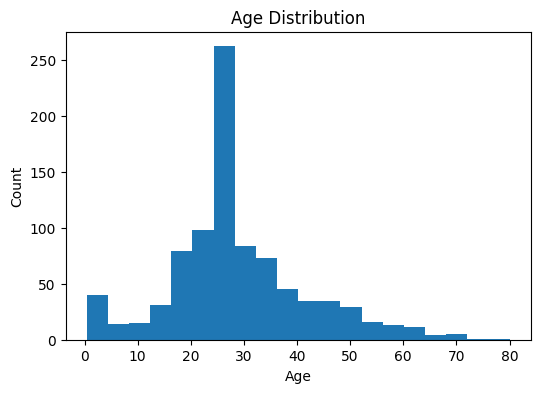

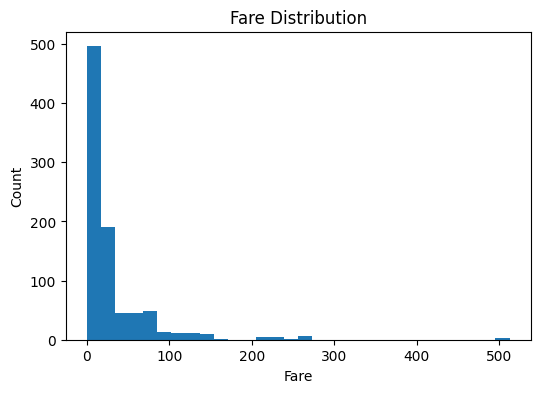

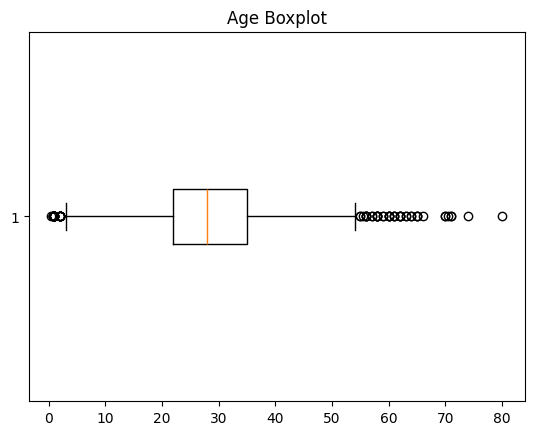

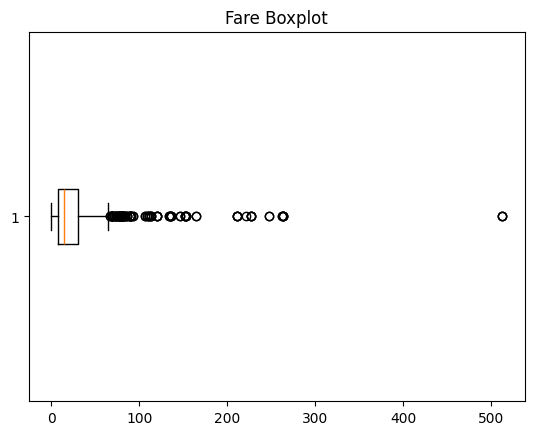

In [4]:
# 6. Visualization
plt.figure(figsize=(6,4))
plt.hist(df['age'], bins=20)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(6,4))
plt.hist(df['fare'], bins=30)
plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Count")
plt.show()

plt.boxplot(df['age'].dropna(), vert=False)
plt.title("Age Boxplot")
plt.show()

plt.boxplot(df['fare'].dropna(), vert=False)
plt.title("Fare Boxplot")
plt.show()



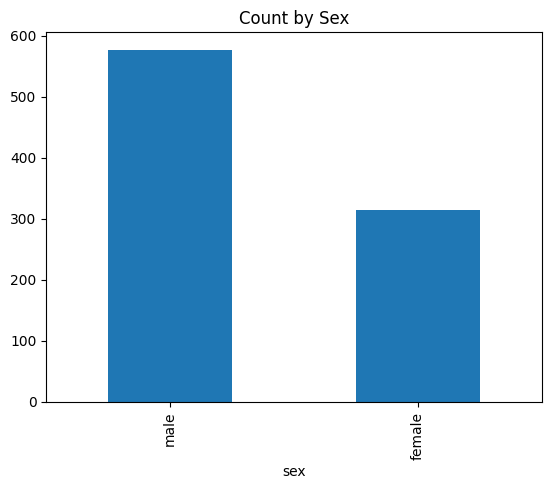

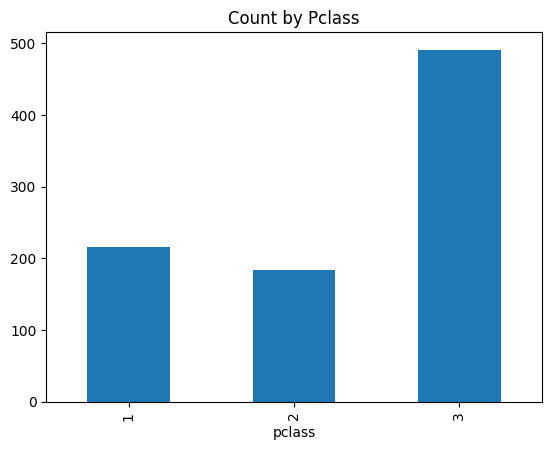

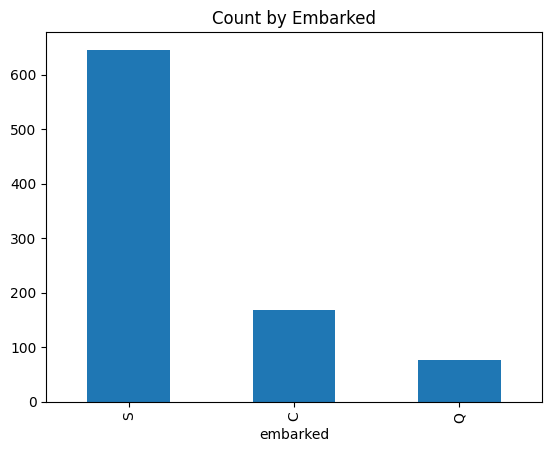

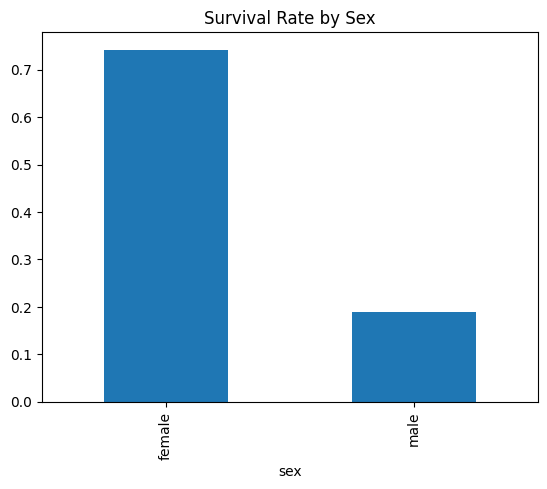

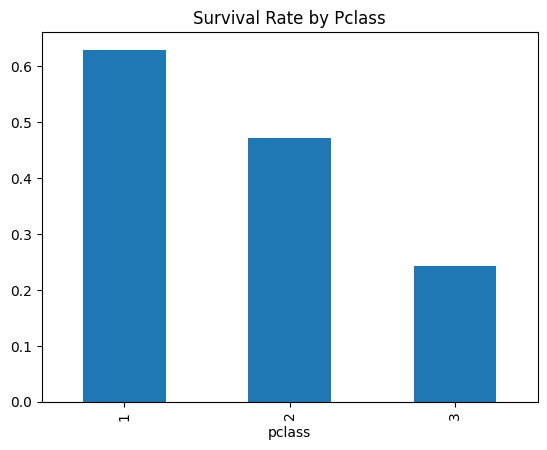

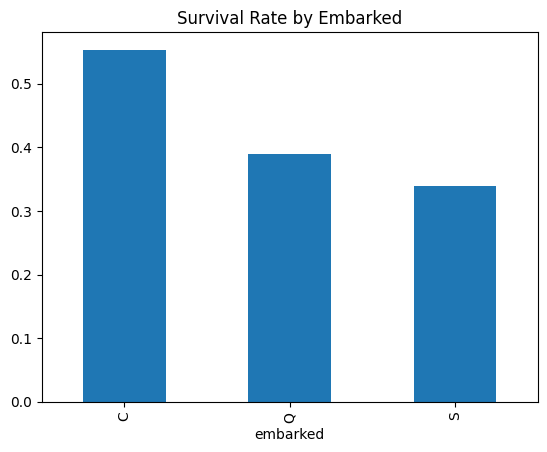

In [5]:
# Count plots
df['sex'].value_counts().plot(kind="bar", title="Count by Sex")
plt.show()

df['pclass'].value_counts().sort_index().plot(kind="bar", title="Count by Pclass")
plt.show()

df['embarked'].value_counts().plot(kind="bar", title="Count by Embarked")
plt.show()

# Survival comparisons
survival_by_sex.plot(kind="bar", title="Survival Rate by Sex")
plt.show()

survival_by_pclass.plot(kind="bar", title="Survival Rate by Pclass")
plt.show()

survival_by_embarked.plot(kind="bar", title="Survival Rate by Embarked")
plt.show()



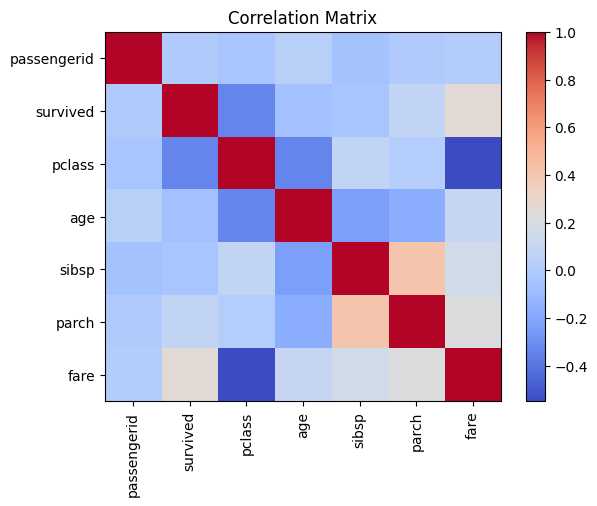

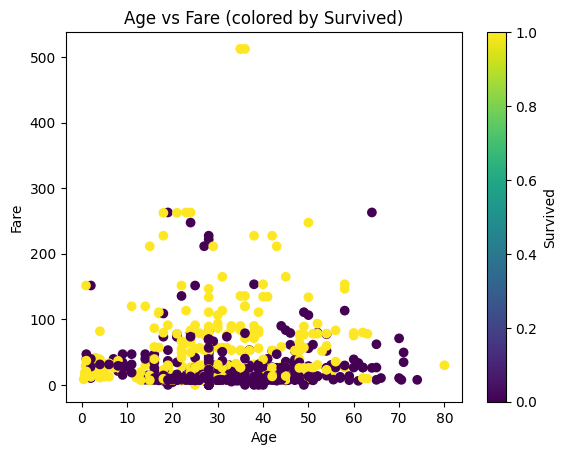

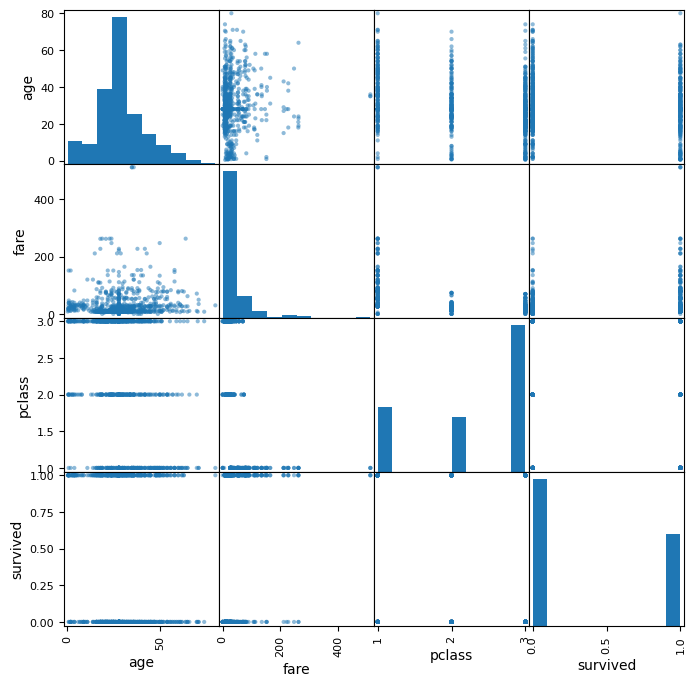

In [6]:
#Correlation heatmap
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Matrix")
plt.show()

# Scatter: Age vs Fare colored by Survival
plt.scatter(df['age'], df['fare'], c=df['survived'])
plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Age vs Fare (colored by Survived)")
plt.colorbar(label="Survived")
plt.show()

# Scatter matrix
scatter_matrix(df[['age','fare','pclass','survived']].dropna(), figsize=(8,8), diagonal="hist")
plt.show()

# 7. Save cleaned dataset
df.to_csv("titanic_cleaned.csv", index=False)
#